# Amortized policy improvement, round 1: does a conservative value head over EI beat EI?

## Description

<!-- Written 2026-11-11 before the first run (pre-registration). Design: research_log/decisions/0003. Issue #13. -->

**Question.** Round 1 of approximate policy iteration from EI (0003 §3): a value head predicts, for every candidate query, its advantage over EI's own pick. The advantage is measured as the ground-truth final regret of querying the candidate and then following EI to the budget. Acting on that head with the conservative rule improves the policy by one step. Does the result beat EI on fresh tasks, and by how much? The answer says whether one improvement step captures a worthwhile planning gap on the PFN's own prior, at EI's cost per step.

**Setup.**
- *Base policy* π₀: EI on the frozen `pfn_large`, on the bo pipeline's candidate generator (1024 shifted Sobol points + 3 × 64 incumbent perturbations). The prior is noise-free (P0), so latent EI = EI.
- *Budget*: n_init = 2d shared Sobol points, T = 10d steps; d = 2 in this pilot.
- *Labels* (0003 §5.2), on 4000 split-4 instances:
  - one behaviour rollout per instance: EI for 80%, UCB(0.99) or PI for 10% each, for off-policy coverage;
  - one branch step t ~ U{0..T−1} per rollout;
  - a candidate set of 133: EI's pick x₀; the argmaxes of UCB 0.9 / 0.99, PI and the mean; 64 shifted Sobol points; 4 × 16 perturbations of the 4 best points at σ ∈ {0.01, 0.03, 0.1};
  - 16 labeled candidates: x₀, the heuristic argmaxes, the top 4 by EI, then random;
  - each labeled candidate is queried and then continued with EI to T, under 4 continuation replicates shared across candidates (common random numbers);
  - label = mean over replicates of R(x₀) − R(c), with R the final regret in % of the task's gap f_med − f\*, plus its standard error.
- *Value head* (0003 §4.4):
  - inputs: the PFN's final query-token state z(x), bar-distribution summaries relative to the incumbent, distances, source, within-set ranks, and global budget / belief features;
  - architecture: an MLP, then FiLM from the global features, then 2 set-transformer layers;
  - outputs: Â anchored at x₀ (Â(x₀) = 0) and σ̂;
  - training: Gaussian NLL with the label's standard error added to the predicted variance; 10% of instances held out for early stopping.
- *Conservative rule* (0003 §3.3): query argmax (Â − c σ̂) only if that maximum is > 0, otherwise x₀.
- *Calibration*: c ∈ {0, 0.5, 1, 2, 3, 4} on 300 split-0 tasks, each paired against EI. c\* = the c with the lowest mean normalized regret (ties go to the larger c). It is fixed before the test run.
- *Test*: 1000 split-1 tasks. Compared: EI; π₁ at c\* (the pre-registered comparison); π₁ at the other c (secondary; not selected on).
- *Null control*: a head trained identically on labels permuted across the candidates of each state, run at c\*. It carries no candidate information, so it must not beat EI. How much it loses shows how well the rule protects.
- Everything is paired on tasks, with common random numbers; fp32.

*Revision after the sanity run (2026-11-11, before the pilot):* the grid of c was {0, 0.5, 1, 2} as in 0003 §5.4. With a 180-state head in the sanity run, every c in it was worse than EI on calibration, and c\* is chosen only within the grid. The grid was therefore extended by 3 and 4, so that a weak head can be made more conservative. Nothing else changed.

**What to look for.**
1. The primary effect: the paired difference Δ = mean_task [R(π₁, c\*) − R(EI)], with its bootstrap 95% CI, absolute and relative to EI's mean R. Secondary: the gain on log₁₀ regret (the project's usual measure).
2. The null head's Δ.
3. The deviation rate per c: how often π₁ leaves EI's pick, and from which candidate sources.
4. Validation fit of the head: Â against the label, per branch step.
5. The cross-fitted *clairvoyant* advantage map: the best labeled candidate is selected on 2 continuation replicates and scored on the other 2. It is the reachable first-order gain within this candidate class, as a diagnostic only. It uses the true task, so it is an upper reference, never a result.

**GO / NO-GO** (rule `analysis/api.py::api_verdict`, worthwhile = 5% relative):
- **INVALID** if the null head beats EI with its CI below 0.
- **GO** if π₁ at c\* lowers mean normalized regret by ≥ 5% relative with the CI of Δ below 0.
- **NO-GO** if the CI rules out a 5% relative gain.
- **INCONCLUSIVE** otherwise.

GO means a confirm run at d ∈ {2, 4} with the same rule, and then round 2. NO-GO at d = 2 means one improvement step from EI on P0 is not worth it at this budget. That supports 0003 §3.6 (EI near a fixed point of policy iteration for this prior), but only for this candidate class and readout.

**Limits.**
- `pfn_large` is valid for n ≤ 100 and d ≤ 6; here the context is ≤ 12d = 24.
- The prior is P0: noise-free and on the global ECDF scale. The noise awareness and budget awareness motivated in 0003 are therefore barely testable; only myopia and PFN-error correction remain.
- One fixed T per d: the budget input is t/T only.
- Deviations from 0003, all for cost or because the components don't exist yet: no two-headed PFN (Stage 0); no context-token pooling in the head; features computed once and kept in memory, not recomputed on load; EI's pick comes from the fixed Sobol + perturbation generator, not Adam refinement; no carry-over candidates; a 4000-state pilot instead of 50k.
- The calibration set (300 tasks) is small, so c\* is noisy. All c are reported on the test split for that reason, but only c\* is the claim.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.api import advantage_map, api_verdict, paired_delta
from anytime_acq.analysis.stats import bootstrap_ci

SNAPSHOT = "results/api_round1/pilot_20261111-133311"
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached pilot experiment=api_round1 task.d=2
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261111-133311` |
| commit | `c0f51e039a6b` (tag `sweep/api_round1/pilot_20261111-133311`) |
| backend / host | detached / ulysses |
| ran | 2026-11-11T13:33:13 → 2026-11-11T15:12:10 |
| members | 1: 1 done |
| compute | 1.6 h wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/api_round1.yaml`):

```yaml
# @package _global_
# Amortized policy improvement, round 1 (research_log/decisions/0003): a value head over EI with the
# conservative rule, against EI. Pre-registration: notebooks/06_2026-11-11_api_round1.ipynb.
# Labels on split 4, c calibrated on split 0, test on split 1 (never selected on).
# Pilot: task.d=2 (then task.d=4 if the budget allows).
defaults:
  - override /task: api

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  api_candidates.local_sigmas: '[0.01, 0.03, 0.1]'
  api_candidates.n_global: 64
  api_candidates.n_local_per_point: 16
  api_candidates.n_top: 4
  calib.cs: '[0.0, 0.5, 1.0, 2.0, 3.0, 4.0]'
  calib.n_tasks: 300
  calib.split: 0
  calib.task_offset: 0
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  device: cuda
  eps: 0.0001
  head.heads: 4
  head.layers: 2
  head.width: 256
  label.behaviour.ei: 0.8
  label.behaviour.pi: 0.1
  label.behaviour.ucb0.99: 0.1
  label.chunk_tasks: 1000
  label.n_cont: 4
  label.n_labeled: 16
  label.n_tasks: 4000
  label.split: 4
  label.task_draw.n_dense: 4096
  label.task_draw.n_refine: 8
  label.task_draw.refine_steps: 50
  label.task_offset: 0
  label.val_frac: 0.1
  n_init_per_d: 2
  name: api
  pfn: pfn_large
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  test.n_tasks: 1000
  test.split: 1
  test.task_offset: 0
  tf32: false
  train.batch: 128
  train.epochs: 60
  train.lr: 0.0003
  train.patience: 8
  train.wd: 0.01
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
S = runs.iloc[0]
C_STAR = float(S["calib/c_star"])
N_CONT = int(snap.constants.get("task.label.n_cont", 4))
times = {k: round(float(S[k]) / 60, 1) for k in runs.columns if k.startswith("time/")}
print("c* (calibrated on split 0):", C_STAR, "| minutes:", times)
labels, calib, test = snap.table("labels"), snap.table("calib"), snap.table("test")
dec, best, fst = snap.table("decisions"), snap.table("best"), snap.table("fstar")
ARM = f"api_c{C_STAR:g}"
NULL = f"null_c{C_STAR:g}"
print("labeled states:", labels.state.nunique(), "| test tasks:", test.task.nunique(), "| arms:", sorted(test.arm.unique()))

member status: {'DONE': 1}
c* (calibrated on split 0): 1.0 | minutes: {'time/calib_s': 3.0, 'time/labels_s': 84.6, 'time/test_s': 11.1, 'time/train_s': 0.2}
labeled states: 4000 | test tasks: 1000 | arms: ['api_c0', 'api_c0.5', 'api_c1', 'api_c2', 'api_c3', 'api_c4', 'ei', 'null_c1']


## 1. Labels: how much is there to gain over EI's pick?

Labels are in % of the task's gap f_med − f\* (positive = the candidate beats EI's pick x₀ after continuing with EI to T).
The cross-fitted advantage map selects the best labeled candidate on 2 continuation replicates and scores it on the other 2.
It is *clairvoyant* (true-task continuations): an upper reference for what one improvement step within this candidate class could reach, not a result.

label mean 0.041 | share > 0: 0.305 | share == 0: 0.360 | mean se 0.205


,count,mean,median,share>0
source,,,,
global,21388,0.093,0.0,0.299
local,27536,0.011,0.0,0.292
mean,3168,-0.019,0.0,0.348
pi,2720,-0.037,0.0,0.350
ucb0.9,2088,-0.036,0.0,0.356
ucb0.99,3100,0.134,0.0,0.347


best_crossfit   mean 0.700  CI [0.574, 0.837]


best_in_sample  mean 0.871  CI [0.738, 1.012]
for scale: EI's mean final normalized regret on the test split = 1.335 (% of gap)


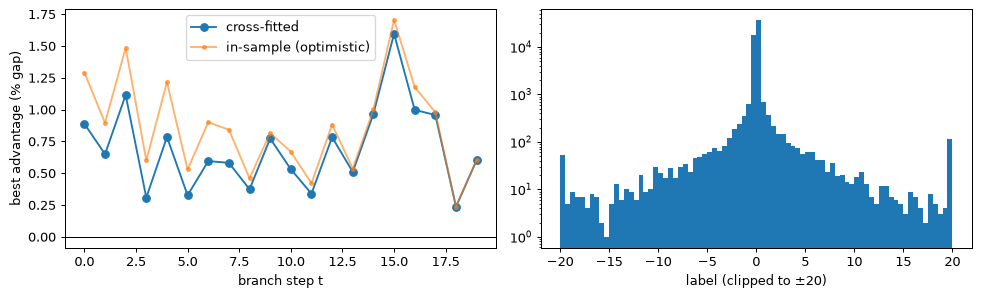

In [ ]:
lab = labels.loc[labels.valid & (labels.j > 0)]
print(f"label mean {lab.adv.mean():.3f} | share > 0: {(lab.adv > 0).mean():.3f} | share == 0: {(lab.adv == 0).mean():.3f} | mean se {lab.se.mean():.3f}")
display(lab.groupby("source").adv.agg(["count", "mean", "median", lambda a: (a > 0).mean()]).rename(columns={"<lambda_0>": "share>0"}).round(3))
am = advantage_map(labels, N_CONT)
for col in ("best_crossfit", "best_in_sample"):
    lo, hi = bootstrap_ci(am[col].to_numpy())
    print(f"{col:15s} mean {am[col].mean():.3f}  CI [{lo:.3f}, {hi:.3f}]")
ei_test_mean = test.loc[test.arm == "ei", "norm_regret"].mean()
print(f"for scale: EI's mean final normalized regret on the test split = {ei_test_mean:.3f} (% of gap)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), dpi=90)
am.groupby("t").best_crossfit.mean().plot(ax=ax[0], marker="o", label="cross-fitted")
am.groupby("t").best_in_sample.mean().plot(ax=ax[0], marker=".", alpha=0.6, label="in-sample (optimistic)")
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_xlabel("branch step t"); ax[0].set_ylabel("best advantage (% gap)"); ax[0].legend()
ax[1].hist(np.clip(lab.adv, -20, 20), bins=80); ax[1].set_yscale("log"); ax[1].set_xlabel("label (clipped to ±20)")
plt.tight_layout(); plt.show()

## 2. Value head: does it predict the labels on held-out instances?

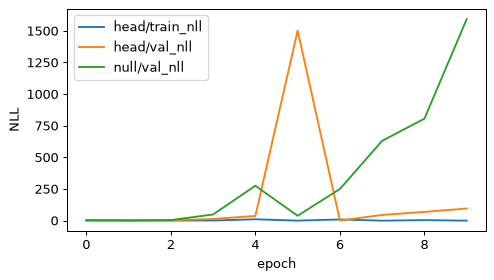

{'head/best_val_nll': 0.3031, 'null/best_val_nll': 1.4224}
validation: n=6450  Pearson r=0.049  Spearman=-0.009  z-score sd=1.06 (1 = calibrated)  share |z|<1.96: 0.979
validation states: label of the head's top labeled candidate: mean 0.033 (x0 = 0); best labeled: 0.892


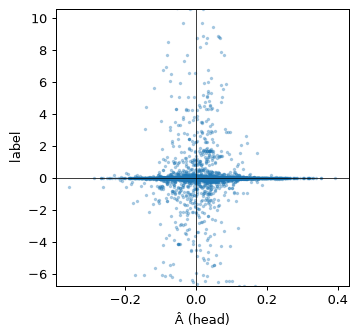

In [ ]:
cur = snap.curves()
fig, ax = plt.subplots(1, 1, figsize=(6, 3.2), dpi=90)
for k in ("head/train_nll", "head/val_nll", "null/val_nll"):
    c = cur.loc[cur.key == k]
    ax.plot(c.step, c.value, label=k)
ax.set_xlabel("epoch"); ax.set_ylabel("NLL"); ax.legend(); plt.show()
print({k: round(float(S[k]), 4) for k in ("head/best_val_nll", "null/best_val_nll")})
v = labels.loc[(labels.split == "val") & labels.valid & (labels.j > 0)]
r = np.corrcoef(v.A_hat, v.adv)[0, 1]
rs = v[["A_hat", "adv"]].rank().corr().iloc[0, 1]
z = (v.adv - v.A_hat) / np.sqrt(v.sigma**2 + v.se**2)
print(f"validation: n={len(v)}  Pearson r={r:.3f}  Spearman={rs:.3f}  z-score sd={z.std():.2f} (1 = calibrated)  share |z|<1.96: {(z.abs() < 1.96).mean():.3f}")
# within-state ranking: does the head's top labeled candidate beat x0 on the labels?
vv = labels.loc[(labels.split == "val") & labels.valid]
top = vv.loc[vv.groupby("state").A_hat.idxmax()]
print(f"validation states: label of the head's top labeled candidate: mean {top.adv.mean():.3f} (x0 = 0); best labeled: {vv.groupby('state').adv.max().mean():.3f}")
fig, ax = plt.subplots(1, 1, figsize=(4.2, 4), dpi=90)
ax.scatter(v.A_hat, v.adv, s=3, alpha=0.3); ax.axhline(0, c="k", lw=0.6); ax.axvline(0, c="k", lw=0.6)
ax.set_xlabel("Â (head)"); ax.set_ylabel("label"); ax.set_ylim(np.percentile(v.adv, [0.5, 99.5])); plt.show()

## 3. Calibration of c (split 0, chosen before the test run)

In [ ]:
cal_rows = [paired_delta(calib, a, "ei", n_boot=5000) for a in sorted(calib.arm.unique()) if a != "ei"]
display(pd.DataFrame(cal_rows)[["a", "n", "delta", "lo", "hi", "rel", "frac_a_better", "frac_tied"]].round(4))
print("c* =", C_STAR)

,a,n,delta,lo,hi,rel,frac_a_better,frac_tied
0,api_c0,300,6.3548,5.1015,7.7285,5.9949,0.0700,0.0833
1,api_c0.5,300,-0.0080,-0.0326,0.0121,-0.0076,0.1133,0.7100
2,api_c1,300,-0.0087,-0.0277,0.0029,-0.0082,0.0633,0.8600
3,api_c2,300,0.0001,0.0000,0.0004,0.0001,0.0000,0.9900
4,api_c3,300,0.0000,0.0000,0.0000,0.0000,0.0000,0.9967
5,api_c4,300,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000


c* = 1.0


## 4. Test (split 1): π₁ against EI, and the null head

Δ = mean_task [R(arm) − R(EI)] in % of the gap (negative = better than EI), with bootstrap 95% CIs over tasks. `rel` is Δ relative to EI's mean R.
The pre-registered comparison is π₁ at c\*. The other c are secondary. The null head (labels permuted) runs at c\*.

In [ ]:
arms = [a for a in sorted(test.arm.unique()) if a != "ei"]
rows = [paired_delta(test, a, "ei") for a in arms]
tab = pd.DataFrame(rows)
lg = [paired_delta(test, a, "ei", col="log_regret") for a in arms]
tab["delta_log10"], tab["log10_lo"], tab["log10_hi"] = [d["delta"] for d in lg], [d["lo"] for d in lg], [d["hi"] for d in lg]
tab["gain_geo"] = 1 - 10 ** tab.delta_log10  # 1 - geometric-mean regret ratio (project convention)
rates = dec.groupby("arm").deviated.mean()
tab["deviation_rate"] = tab.a.map(rates)
display(tab[["a", "n", "delta", "lo", "hi", "rel", "rel_lo", "rel_hi", "frac_a_better", "frac_tied", "gain_geo", "deviation_rate"]].round(4))
print(test.groupby("arm")[["norm_regret", "log_regret"]].mean().round(4))
print("Note: lanes of different heads run in different batches; fp32 batch-shape effects then move a few near-tie picks, so a non-deviating arm can differ from EI by ~1e-4 on a few tasks.")

,a,n,delta,lo,hi,rel,rel_lo,rel_hi,frac_a_better,frac_tied,gain_geo,deviation_rate
0,api_c0,1000,5.9778,5.3066,6.6739,4.4783,3.9755,4.9999,0.078,0.077,-11.2082,0.9542
1,api_c0.5,1000,0.0605,-0.0124,0.1785,0.0453,-0.0093,0.1337,0.135,0.674,-0.0526,0.1814
2,api_c1,1000,-0.0101,-0.0329,0.0021,-0.0076,-0.0246,0.0016,0.047,0.882,-0.0051,0.0582
3,api_c2,1000,-0.0155,-0.0476,0.0012,-0.0116,-0.0356,0.0009,0.013,0.972,0.0030,0.0130
4,api_c3,1000,-0.0159,-0.0480,0.0003,-0.0119,-0.0359,0.0002,0.004,0.990,0.0041,0.0044
5,api_c4,1000,-0.0161,-0.0484,0.0000,-0.0121,-0.0362,0.0000,0.002,0.996,0.0051,0.0021
6,null_c1,1000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.429,0.157,0.0001,0.0008


          norm_regret  log_regret
arm                              
api_c0         7.3126     -2.4259
api_c0.5       1.3953     -3.4903
api_c1         1.3247     -3.5104
api_c2         1.3194     -3.5139
api_c3         1.3189     -3.5144
api_c4         1.3187     -3.5148
ei             1.3348     -3.5126
null_c1        1.3348     -3.5126
Note: lanes of different heads run in different batches; fp32 batch-shape effects then move a few near-tie picks, so a non-deviating arm can differ from EI by ~1e-4 on a few tasks.


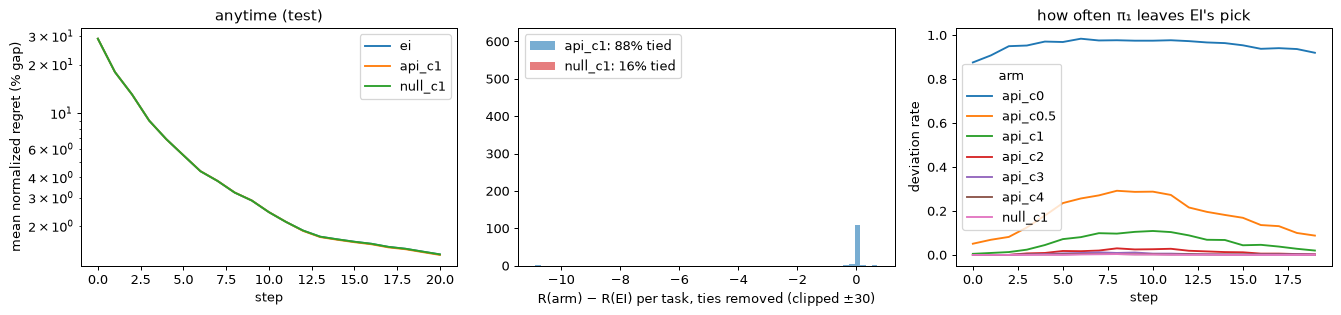

arm,api_c1,null_c1
source,,
global,139,16
local,816,0
mean,94,0
pi,41,0
ucb0.9,28,0
ucb0.99,47,0


In [ ]:
nr = best.merge(fst[["task", "fstar", "fmed"]], on="task")
nr["R"] = 100 * (nr.best_f - nr.fstar).clip(lower=0) / (nr.fmed - nr.fstar)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), dpi=90)
for a in ("ei", ARM, NULL):
    m = nr.loc[nr.arm == a].groupby("t").R.mean()
    ax[0].plot(m.index, m.values, label=a)
ax[0].set_yscale("log"); ax[0].set_xlabel("step"); ax[0].set_ylabel("mean normalized regret (% gap)"); ax[0].legend(); ax[0].set_title("anytime (test)")
p = test.pivot_table(index="task", columns="arm", values="norm_regret")
for a, c in ((ARM, "C0"), (NULL, "C3")):
    dlt = (p[a] - p["ei"]).to_numpy()
    ax[1].hist(np.clip(dlt[dlt != 0], -30, 30), bins=60, alpha=0.6, color=c, label=f"{a}: {np.mean(dlt == 0):.0%} tied")
ax[1].set_xlabel("R(arm) − R(EI) per task, ties removed (clipped ±30)"); ax[1].legend()
dr = dec.groupby(["arm", "step"]).deviated.mean().unstack(0)
dr[[c for c in dr.columns if c != "ei"]].plot(ax=ax[2]); ax[2].set_ylabel("deviation rate"); ax[2].set_title("how often π₁ leaves EI's pick")
plt.tight_layout(); plt.show()
dd = dec.loc[dec.deviated & dec.arm.isin([ARM, NULL])]
display(dd.groupby(["arm", "source"]).size().unstack(0).fillna(0).astype(int))

## Observations

Numbers are from the cells above, snapshot `pilot_20261111-133311`: d = 2; 4000 label states; c calibrated on 300
split-0 tasks; tested on 1000 split-1 tasks; 1/1 member DONE. Extra breakdowns of the same snapshot are in log entry §2.

1. **There is headroom over EI's pick, with task knowledge, and it is concentrated.**
   - The cross-fitted best of the 16 labeled candidates beats x₀ by **0.70 [0.57, 0.84] % of the gap** per state. For
     scale, EI's mean final normalized regret on the test split is 1.34. The in-sample value (0.87) is higher, which is
     the optimizer's curse.
   - The headroom is present at every stage of the run (0.53 to 0.89 by quarter of T).
   - It sits in a few states. Labels are heavy-tailed: median 0, 36% exactly 0, 1st/99th percentiles −4.5 / +5.0. The
     top 10% of states carry about all of the net advantage.
   - The global-Sobol and UCB(0.99) candidates have positive mean labels (+0.09, +0.13). In some states EI is stuck,
     and exploring pays a lot.
   - This is a *clairvoyant* reference: its continuations run on the true task. It is not a deployable result.
2. **The value head did not learn to rank candidates.**
   - On validation states: Pearson r = 0.05 and Spearman −0.01 between Â and the label.
   - The label of the head's top labeled candidate averages 0.03 (x₀ = 0; best labeled: 0.89).
   - Â has sd 0.075 against a label sd of 2.1. The head predicts about zero everywhere and explains the labels through
     σ̂: its NLL (0.30) beats the null head's (1.42), and its z-scores are calibrated (sd 1.06). Early stopping kept
     epoch 2.
   - In short, the Gaussian NLL on heavy-tailed, seed-averaged labels was minimized by modelling the spread, not the
     mean.
3. **The conservative rule did its job.**
   - Without it (c = 0), π₁ deviates on 95% of steps and is far worse than EI: Δ = +5.98 % of gap, +448%.
   - At the calibrated c\* = 1, π₁ deviates on 5.8% of steps (mostly to local perturbations), and
     Δ = −0.010 [−0.033, +0.002] (−0.8% relative).
   - At larger c the deviation rate goes toward 0 and Δ toward 0.
   - The null head deviates on 0.08% of steps (Δ = 0): the fallback works when the head carries no information.
4. **Verdict by the pre-registered rule: NO-GO.** The CI of π₁'s relative gain [−2.5%, +0.2%] rules out the
   worthwhile 5%. The NO-GO is about *this head*, not about the headroom: per point 1, a policy that could recognise
   the rare states where deviating pays would have room to gain. This pilot can't tell whether the head failed
   because the information is not readable from the PFN state or because of how it was trained (loss, data size).


## Verdict

In [ ]:
main = paired_delta(test, ARM, "ei")
null = paired_delta(test, NULL, "ei")
verdict = api_verdict(main, null)
print(f"pi_1 (c*={C_STAR:g}) vs EI: delta {main['delta']:.4f} [{main['lo']:.4f}, {main['hi']:.4f}] % gap, rel {main['rel']:+.1%} [{main['rel_lo']:+.1%}, {main['rel_hi']:+.1%}]")
print(f"null head vs EI:           delta {null['delta']:.4f} [{null['lo']:.4f}, {null['hi']:.4f}]")
print("VERDICT (pre-registered rule):", verdict)

pi_1 (c*=1) vs EI: delta -0.0101 [-0.0329, 0.0021] % gap, rel -0.8% [-2.5%, +0.2%]
null head vs EI:           delta -0.0000 [-0.0000, 0.0000]
VERDICT (pre-registered rule): NO-GO
